In [2]:
import numpy as np


Question 1

In [3]:
n = 1000


1.1 

In [4]:
X1 = np.random.gamma(shape=4,scale=1,size=n)
C1 = np.random.exponential(scale=10,size=n)
Z1 = np.minimum(X1,C1)
delta1 = np.where(X1 <= C1,1,0)
taux1 = np.sum(delta1)/n
print(taux1)


0.685


1.2

In [5]:
U = np.random.gamma(2,0.5,size=n)
V = np.random.gamma(16,0.25,size=n)
B = np.random.binomial(1,0.4,size=n)
X2 = B*U + (1-B)*V
C2 = np.random.exponential(scale=4,size=n)
Z2 = np.minimum(X2,C2)
delta2 = np.where(X2 <= C2,1,0)
taux2 = np.sum(delta2)/n
print(taux2)

0.532


Question 2

In [6]:
#def base_trigo(a,D,x):
#    d = (D-1)//2 
#    phi = np.zeros(D)
#    indicatrice = np.where((x>=0)&(x<=a),1,0)
#    phi[0] = 1 
#    for j in range(1,d+1):
#        phi[2*j-1] = np.sqrt(2/a)*np.cos(2*np.pi*j*(x/a))*indicatrice
#        phi[2*j] = np.sqrt(2/a)*np.sin(2*np.pi*j*(x/a))*indicatrice
#  return phi


def base_trigo(a,j,x):
    indicatrice = np.where((x>=0)&(x<=a),1,0)
    if j == 0 : 
        phi = 1 
    elif j%2==1: 
        k = (j+1)//2 
        phi = np.sqrt(2/a)*np.cos(2*np.pi*k*x/a)
    else:
        k = j//2 
        phi = np.sqrt(2/a)*np.sin(2*np.pi*k*x/a)
    return phi*indicatrice
    
    


In [7]:
def base_trigo(a,D,x):
    d = (D-1)//2 
    phi = np.zeros(D)
    indicatrice = np.where((x>=0)&(x<=a),1,0)
    phi[0] = 1/np.sqrt(a)*indicatrice
    for j in range(1,d+1):
        phi[2*j-1] = np.sqrt(2/a)*np.cos(2*np.pi*j*(x/a))*indicatrice
        phi[2*j] = np.sqrt(2/a)*np.sin(2*np.pi*j*(x/a))*indicatrice
    return phi

def bj_trigo(a,D,Z,delta): 
    n = len(Z)
    b = np.zeros(D)
    for i in range(n):
        b = b + delta[i]*base_trigo(a,D,Z[i])
    b = b/n
    return b 

def estim_trigo(a,D,Z,delta,x):
    return np.sum(bj_trigo(a,D,Z,delta)*base_trigo(a,D,x))

for D in [3,5,7,9]:
    print(estim_trigo(12,D,Z1,delta1,2))

        

0.11126701577396017
0.1263536517355224
0.13700784366264157
0.1459001316409926


In [8]:
def base_histo(a,D,x):
    phi = np.zeros(D)
    for j in range(0,D):
        indicatrice = np.where((x>=a*j/D)&(x<a*(j+1)/D),1,0)
        phi[j] = np.sqrt(D/a)*indicatrice
    return phi 

def bj_histo(a,D,Z,delta):
    n = len(Z)
    b = np.zeros(D)
    for i in range(n):
        b = b + delta[i]*base_histo(a,D,Z[i])
    b = b/n
    return b 

def estim_histo(a,D,Z,delta,x):
    return np.sum(bj_histo(a,D,Z,delta)*base_histo(a,D,x))

for D in [10,15]:
    print(estim_histo(12,D,Z1,delta1,2))


0.13416666666666635
0.15000000000000024


Question 3

In [9]:
from scipy.stats import gamma 

In [10]:
def psi_modele1(x):
    f = gamma.pdf(x,a=4,scale=1)
    Sc = np.exp(-x/10)
    return f*Sc

def psi_modele2(x):
    u = gamma.pdf(x,a=2,scale=1/2)
    v = gamma.pdf(x,a=16,scale=1/4)
    f = 0.4*u + 0.6*v 
    Sc = np.exp(-x/4)
    return f*Sc

In [11]:
x1 = np.linspace(0,12,1000)
x2 = np.linspace(0,6,1000)
psi1 = psi_modele1(x1)
psi2 = psi_modele2(x2)


In [12]:
bj_trigo1 = bj_trigo(12,7,Z1,delta1)
estim_modele1_trigo = np.zeros(len(x1))
for i in range(len(x1)) : 
    estim_modele1_trigo[i] = np.sum(bj_trigo1*base_trigo(12,7,x1[i]))


In [13]:
bj_histo1 = bj_histo(12,15,Z1,delta1)
estim_modele1_histo = np.zeros(len(x1))
for i in range(len(x1)):
    estim_modele1_histo[i] = np.sum(bj_histo1*base_histo(12,15,x1[i]))

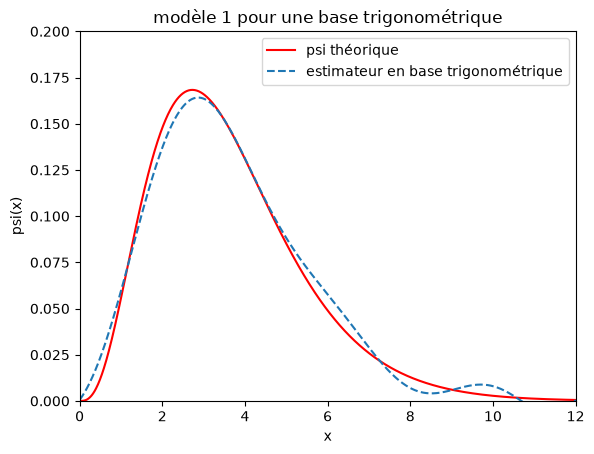

In [14]:
import matplotlib.pyplot as plt 
plt.plot(x1,psi1,color="red",label="psi théorique")
plt.plot(x1,estim_modele1_trigo,linestyle="--",label = "estimateur en base trigonométrique")
plt.xlim(0,12)
plt.ylim(0,0.20)
plt.xlabel("x")
plt.ylabel("psi(x)")
plt.title("modèle 1 pour une base trigonométrique")
plt.legend()
plt.show()

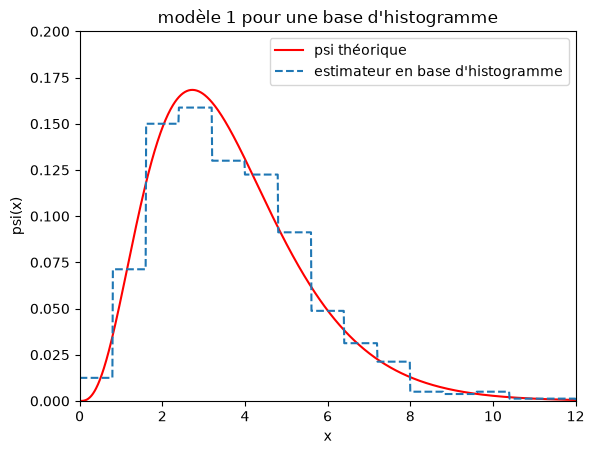

In [15]:
plt.plot(x1,psi1,color = "red",label = "psi théorique")
plt.plot(x1,estim_modele1_histo,linestyle="--",label="estimateur en base d'histogramme")
plt.xlim(0,12)
plt.ylim(0,0.20)
plt.xlabel("x")
plt.ylabel("psi(x)")
plt.title("modèle 1 pour une base d'histogramme")
plt.legend()
plt.show()

modèle 2

In [16]:
bj_trigo2 = bj_trigo(6,7,Z2,delta2)
estim_modele2_trigo = np.zeros(len(x2))
for i in range(len(x2)) : 
    estim_modele2_trigo[i] = np.sum(bj_trigo2*base_trigo(6,7,x2[i]))

In [17]:
bj_histo2 = bj_histo(6,15,Z2,delta2)
estim_modele2_histo = np.zeros(len(x2))
for i in range(len(x2)):
    estim_modele2_histo[i] = np.sum(bj_histo2*base_histo(6,15,x2[i]))

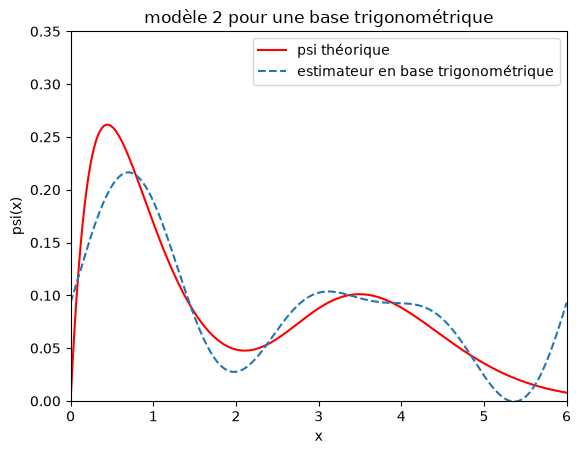

In [18]:
plt.plot(x2,psi2,color="red",label="psi théorique")
plt.plot(x2,estim_modele2_trigo,linestyle="--",label = "estimateur en base trigonométrique")
plt.xlim(0,6)
plt.ylim(0,0.35)
plt.xlabel("x")
plt.ylabel("psi(x)")
plt.title("modèle 2 pour une base trigonométrique")
plt.legend()
plt.show()

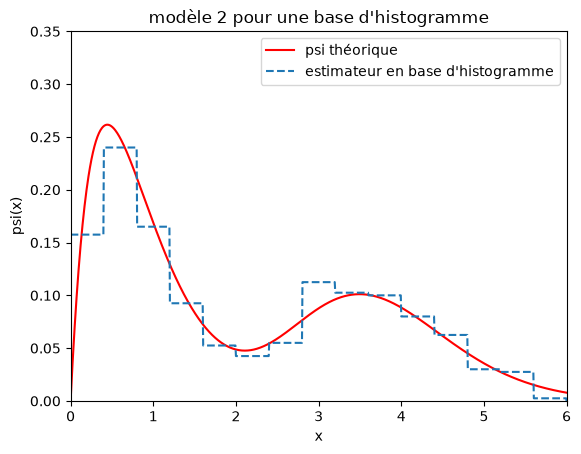

In [19]:
plt.plot(x2,psi2,color = "red",label = "psi théorique")
plt.plot(x2,estim_modele2_histo,linestyle="--",label="estimateur en base d'histogramme")
plt.xlim(0,6)
plt.ylim(0,0.35)
plt.xlabel("x")
plt.ylabel("psi(x)")
plt.title("modèle 2 pour une base d'histogramme")
plt.legend()
plt.show()

Question 4